# Ablation of the selection procedure

This notebook measures AutoHybTS's **own procedure** (§30.5 of the specification): four ways of choosing the final model, with **the same search budget** and **the same external tests**.

| Procedure | What it does |
|---|---|
| `lowest_error` | the finalist with the lowest error on `V_select`, no thresholds |
| `incremental` | the guarded incremental chain (gain ≥ 5%, wins ≥ 60%, variability), all families |
| `incremental_simple` | the same chain, only structures with up to 2 models (standalone and additive hybrid) |
| `guarded_nested` | like `incremental`; if nested CV (with the same families) says the procedure does not beat "the best base of the inner selection", the best base is kept |

The series are synthetic and daily, with three levels (strata) of residual predictability: AR(0) (nothing to correct), AR(0.5) and AR(0.8). Each series keeps its last 14 points as the sealed external test. Besides the best base chosen on `V_select`, each row holds the external error of `naive` and `seasonal_naive` as simple references.

The budget limits only the **number of candidates** (no clock), so the run is reproducible on another machine. The cost of each procedure includes everything it runs: search, selection and, for `guarded_nested`, the inner searches of nested CV.

> The external test is **for reporting only**. Do not pick the "winning" procedure with it: that would repeat the very mistake the ablation wants to measure.

This is a small executable demonstration: 3 synthetic series, one seed, smoke budget and 2 validation origins per layer. It checks the workflow and does not estimate scientific performance. Freeze a separate research protocol; `fold="auto"` resolves up to 7 origins per layer. Historical outputs from the 1% rule are not reused.


In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

import autohybts
from autohybts.benchmarks import (
    PROCEDURES,
    ablation_protocol,
    ablation_report,
    ablation_uncertainty,
    run_ablation,
    synthetic_cases,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## Questions

1. **Losses:** is guarded selection (`incremental`, `guarded_nested`) worse than the best base in fewer cases than `lowest_error`?
2. **Useful gains:** when the residual is predictable (AR(0.8)), do the guarded procedures still choose the hybrid and beat the base?
3. **Complexity:** how much complexity (hybrids, fitted models) does each procedure accept when there is nothing to learn (AR(0))?
4. **Cost:** how much does each procedure cost, counting nested CV?

The answers hold only for these series, this horizon and this budget.

## 1. Configuration

In [2]:
N_SERIES = 3
SEEDS = (0,)
BUDGET = "smoke"
SPACE = {
    "fold": 2,
    "base_models": ("naive", "seasonal_naive", "linear"),
    "correctors": ("linear",),
    "residual_windows": (7,),
    "alphas": (1.0,),
}

cases = list(synthetic_cases(N_SERIES))
protocol = ablation_protocol(cases, SEEDS, BUDGET, space=SPACE)
print("budget:", protocol["budget"])
pd.DataFrame(protocol["series"])

budget: {'preset': 'smoke', 'guard': {'mode': 'standard', 'max_trials_total': 10, 'max_trials_per_family': 4, 'max_candidates_per_stage': 6, 'max_refinements': 1, 'top_k_per_family': 2, 'top_k_residual_structures': 2, 'require_full_pairing': True, 'prefer_simpler_on_tie': True, 'allow_test_feedback_to_search': False}}


,series_id,length,horizon,test_size,seasonal_period,stratum,data_fingerprint,source
0,syn0-phi0.0,400,14,14,7,phi=0.0,b64bb225f3693786c6ac6a32a8a3d029d9ed64a1c665b2...,{}
1,syn1-phi0.5,400,14,14,7,phi=0.5,1bb5738517951a6bd9239cc84bc1e872459cfd5b04b2fa...,{}
2,syn2-phi0.8,400,14,14,7,phi=0.8,ee5d0e4d2cda098925d7f6be165c10927a37bc5d185de9...,{}


## 2. Run

For each series and seed: one search with every family (used by `lowest_error`, `incremental` and `guarded_nested`), one restricted search (`incremental_simple`) and nested CV (`guarded_nested`). Each candidate is evaluated **only once** on the external test.

In [3]:
started = time.perf_counter()
table = run_ablation(cases, seeds=SEEDS, budget=BUDGET, space=SPACE)
print(f"{len(table)} rows in {(time.perf_counter() - started) / 60:.1f} min")
print("search stops:", table["stop_reason"].value_counts().to_dict())
print(
    "prunes by limit:",
    table.drop_duplicates(["series_id", "seed", "search"])["pruned_by"].value_counts().to_dict(),
)
table[["series_id", "seed", "procedure", "champion", "test_score", "gain_vs_base"]].head(8)

12 rows in 3.2 min
search stops: {'max_trials_total': 9, 'budget_limited': 3}


prunes by limit: {'max_trials_per_family:3;max_trials_total:5': 3, 'max_trials_per_family:1': 3}


,series_id,seed,procedure,champion,test_score,gain_vs_base
0,syn0-phi0.0,0,lowest_error,"comb(linear,seasonal_naive)",0.918190,0.115798
1,syn0-phi0.0,0,incremental,"comb(linear,seasonal_naive)",0.918190,0.115798
2,syn0-phi0.0,0,incremental_simple,linear,0.916736,0.117199
3,syn0-phi0.0,0,guarded_nested,seasonal_naive,1.038440,0.000000
4,syn1-phi0.5,0,lowest_error,linear-linear,0.824160,0.280218
5,syn1-phi0.5,0,incremental,linear,1.145013,0.000000
6,syn1-phi0.5,0,incremental_simple,linear,1.145013,0.000000
7,syn1-phi0.5,0,guarded_nested,linear,1.145013,0.000000


## 3. Summary per procedure

* `median_gain_vs_base`: median gain on the test against the best standalone base on `V_select` (positive = better).
* `beats_base_share`, `ties_base_share`, `worse_than_base_share`: fractions of cases better than, equal to and worse than that base.
* `hybrid_share` and `mean_complexity`: fraction of hybrids chosen and mean number of models fitted in the structure.
* `mean_gap`: test error minus `V_select` error (positive = validation was optimistic).
* `mean_rank`: mean rank on the test among the 4 procedures (lower = better).
* `mean_seconds`, `candidates`, `units`: mean cost of the procedure (without the final refit or the reading of the test).
* `seed_std_of_median_gain`: how much the median gain varies across seeds.

In [4]:
report = ablation_report(table)
report.round(4)

,median_gain_vs_base,beats_base_share,ties_base_share,worse_than_base_share,n_rows,n_paired,hybrid_share,mean_complexity,mean_gap,mean_rank,coverage,mean_seconds,candidates,units,seed_std_of_median_gain,n_invalid_gain,paired_coverage
procedure,,,,,,,,,,,,,,,,,
lowest_error,0.1158,1.0000,0.0000,0.0,3,3,1.0000,2.0000,-0.2218,2.0000,1.0,22.5559,10.0,30.0,NaN,0,1.0
incremental,0.1011,0.6667,0.3333,0.0,3,3,0.6667,1.6667,-0.1194,2.6667,1.0,22.5559,10.0,30.0,NaN,0,1.0
incremental_simple,0.1172,0.6667,0.3333,0.0,3,3,0.0000,1.0000,-0.1985,1.6667,1.0,1.9909,7.0,20.0,NaN,0,1.0
guarded_nested,0.0000,0.0000,1.0000,0.0,3,3,0.0000,1.0000,-0.0961,3.6667,1.0,61.8794,30.0,90.0,NaN,0,1.0


### Uncertainty

The seeds of a series are not independent: each series' gain is summarized (median across seeds) and the 95% interval resamples **series**.

In [5]:
ablation_uncertainty(table).round(4)

,n_series,n_paired_series,n_invalid_series,paired_series_coverage,median_gain_vs_base,ci_low,ci_high,better_share,worse_share
procedure,,,,,,,,,
lowest_error,3,3,0,1.0,0.1158,0.1011,0.2802,1.0000,0.0
incremental,3,3,0,1.0,0.1011,0.0000,0.1158,0.6667,0.0
incremental_simple,3,3,0,1.0,0.1172,0.0000,0.1309,0.6667,0.0
guarded_nested,3,3,0,1.0,0.0000,0.0000,0.0000,0.0000,0.0


## 4. By level of residual predictability

When the residual is white noise (AR(0)), a hybrid has nothing to learn: a good procedure should keep the base. With AR(0.8), there is something to correct.

First, each case as a point (ties with the base stay visible in grey); then, per stratum, the fraction of cases better than, equal to and worse than the base.

In [6]:
by_stratum = ablation_report(table, by="stratum")
columns = ["median_gain_vs_base", "beats_base_share", "worse_than_base_share", "hybrid_share"]
by_stratum[columns].round(3)

median_gain_vs_base  beats_base_share  worse_than_base_share  hybrid_share
stratum procedure                                                                                     
phi=0.0 lowest_error                      0.116               1.0                    0.0           1.0
        incremental                       0.116               1.0                    0.0           1.0
        incremental_simple                0.117               1.0                    0.0           0.0
        guarded_nested                    0.000               0.0                    0.0           0.0
phi=0.5 lowest_error                      0.280               1.0                    0.0           1.0
        incremental                       0.000               0.0                    0.0           0.0
        incremental_simple                0.000               0.0                    0.0           0.0
        guarded_nested                    0.000               0.0                    0.0           0.0
phi=0.8 lowest_error                      0.101               1.0                    0.0           1.0
        incremental                       0.101               1.0                    0.0           1.0
        incremental_simple                0.131               1.0                    0.0           0.0
        guarded_nested                    0.000               0.0                    0.0           0.0

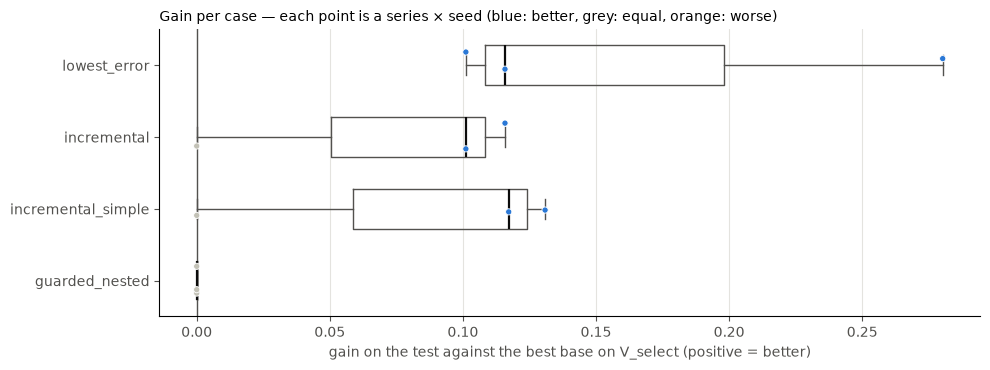

In [7]:
# Visual: thin marks, recessive grid, one colour per meaning (better / tie / worse).
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BETTER, TIE, WORSE = "#2a78d6", "#c3c2b7", "#eb6834"
order = list(PROCEDURES)


def clean(ax, grid_axis="x"):
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)


def cases(ax, column, xlabel, signed=True):
    """Box per procedure with every case on top (zeros stay visible).

    ``signed`` colours points by better / tie / worse; otherwise they stay neutral.
    """
    rng = np.random.default_rng(0)
    for row, procedure in enumerate(order):
        values = table.loc[table["procedure"] == procedure, column].to_numpy()
        ax.boxplot(
            values,
            positions=[row],
            orientation="horizontal",
            widths=0.55,
            showfliers=False,
            medianprops={"color": INK, "linewidth": 1.6},
            boxprops={"color": MUTED},
            whiskerprops={"color": MUTED},
            capprops={"color": MUTED},
        )
        colors = np.where(values > 0, BETTER, np.where(values < 0, WORSE, TIE)) if signed else MUTED
        ax.scatter(
            values,
            row + rng.uniform(-0.2, 0.2, values.size),
            s=20,
            c=colors,
            edgecolors="white",
            linewidths=0.6,
            zorder=3,
        )
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()  # same top-to-bottom order as the stacked bars
    ax.set_xlabel(xlabel, color=MUTED)
    clean(ax)


fig, ax = plt.subplots(figsize=(10, 3.8))
cases(ax, "gain_vs_base", "gain on the test against the best base on V_select (positive = better)")
ax.set_title(
    "Gain per case — each point is a series × seed (blue: better, grey: equal, orange: worse)",
    loc="left",
    fontsize=10,
)
fig.tight_layout()

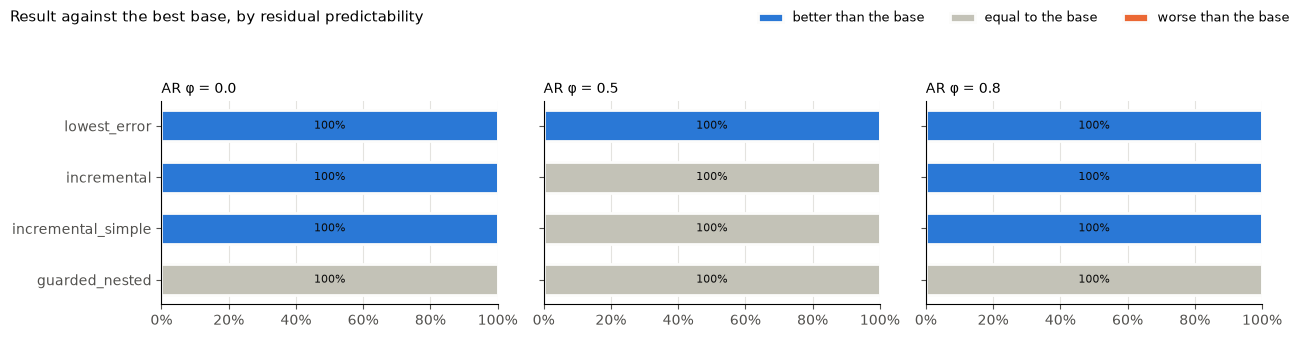

In [8]:
labels = {"better": BETTER, "equal": TIE, "worse": WORSE}
outcome = np.select(
    [table["gain_vs_base"] > 0, table["gain_vs_base"] < 0], ["better", "worse"], "equal"
)
shares = (
    table.assign(result=outcome)
    .groupby(["stratum", "procedure"])["result"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .reindex(columns=list(labels), fill_value=0)
)
strata = sorted(table["stratum"].unique())
fig, axes = plt.subplots(1, len(strata), figsize=(13, 3.4), sharey=True)
for ax, stratum in zip(axes, strata, strict=True):
    part = shares.loc[stratum].reindex(order[::-1])
    left = np.zeros(len(part))
    for label, color in labels.items():
        values = part[label].to_numpy()
        ax.barh(
            part.index,
            values,
            left=left,
            color=color,
            height=0.6,
            edgecolor="#fcfcfb",
            linewidth=2,
            label=label,
        )
        for y, (value, start) in enumerate(zip(values, left, strict=True)):
            if value >= 0.12:
                ax.text(
                    start + value / 2,
                    y,
                    f"{value:.0%}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color=INK,
                )
        left += values
    ax.set_title(stratum.replace("phi=", "AR φ = "), loc="left", fontsize=10)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    clean(ax)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    [f"{n} than the base" if n != "equal" else "equal to the base" for n in names],
    loc="upper right",
    ncol=3,
    frameon=False,
    fontsize=9,
)
fig.suptitle(
    "Result against the best base, by residual predictability", x=0.01, ha="left", fontsize=11
)
fig.tight_layout(rect=(0, 0, 1, 0.9))

## 5. Validation optimism

Gap = test error − `V_select` error. A procedure that picks by the lowest error tends to grab the candidate that got lucky in validation; the gap shows how much of that shows up on the test.

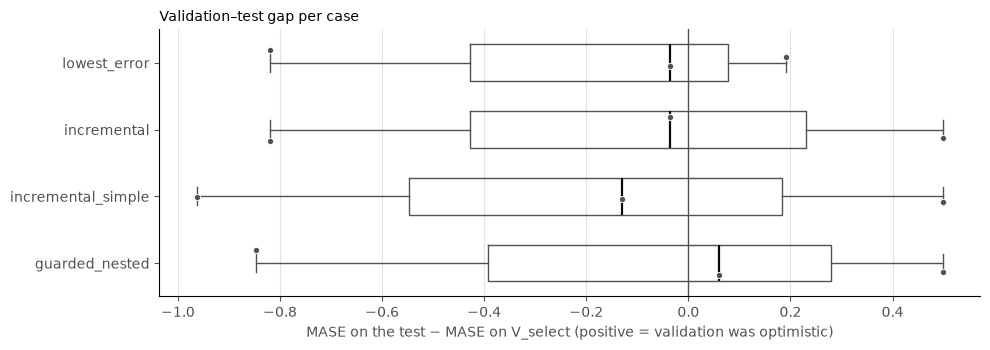

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.6))
cases(
    ax,
    "gap",
    "MASE on the test − MASE on V_select (positive = validation was optimistic)",
    signed=False,
)
ax.set_title("Validation–test gap per case", loc="left", fontsize=10)
fig.tight_layout()

## 6. Cost

Seconds per phase (mean per case) and work done. `lowest_error`, `incremental` and `guarded_nested` share the same search (column `search`): their search cost is the same work, not three measurements. `guarded_nested` adds the inner searches of nested CV (`nested_candidates`). `seconds_refit` (refit of the chosen model before the test) and `seconds_external` (reading of the test) are reported only, not a cost of the procedure.

In [10]:
cost_columns = [
    "seconds",
    "seconds_search",
    "seconds_selection",
    "seconds_nested",
    "seconds_refit",
    "seconds_external",
    "candidates",
    "search_candidates",
    "nested_candidates",
    "pruned_candidates",
    "units",
    "max_trials_total",
]
table.groupby("procedure")[cost_columns].mean().loc[order].round(2)

,seconds,seconds_search,seconds_selection,seconds_nested,seconds_refit,seconds_external,candidates,search_candidates,nested_candidates,pruned_candidates,units,max_trials_total
procedure,,,,,,,,,,,,
lowest_error,22.56,21.37,1.18,0.00,0.08,0.02,10.0,10.0,0.0,8.0,30.0,10.0
incremental,22.56,21.37,1.18,0.00,0.04,0.02,10.0,10.0,0.0,8.0,30.0,10.0
incremental_simple,1.99,1.41,0.58,0.00,0.00,0.02,7.0,7.0,0.0,1.0,20.0,10.0
guarded_nested,61.88,21.37,1.18,39.32,0.00,0.01,30.0,10.0,20.0,8.0,90.0,10.0


## 7. Chosen structures and simple references

In [11]:
chosen = table.groupby("procedure")["champion"].value_counts().unstack(fill_value=0).T
references = table.drop_duplicates(["series_id", "seed"])[
    ["best_base_test", "naive_test", "seasonal_naive_test"]
].median()
print("median test MASE of the references:", references.round(3).to_dict())
chosen

median test MASE of the references: {'best_base_test': 1.038, 'naive_test': 1.744, 'seasonal_naive_test': 1.038}


procedure,guarded_nested,incremental,incremental_simple,lowest_error
champion,,,,
"comb(linear,seasonal_naive)",0,1,0,1
linear,1,1,3,0
linear-linear,0,0,0,1
ma(linear-linear),0,1,0,1
seasonal_naive,2,0,0,0


## 8. Table and resolved protocol

Outputs go to `artifacts/ablation/` (outside git). Resumable CLI demo: `python -m autohybts.benchmarks.ablation --config tools/protocols/ablation_demo.json --checkpoint artifacts/demo.sqlite --out artifacts/demo.csv`; add `--resume` to continue. This smaller CLI example uses one series.


In [12]:
import json
from pathlib import Path

folder = Path("artifacts") / "ablation"
folder.mkdir(parents=True, exist_ok=True)
table.to_csv(folder / "ablation.csv", index=False)
(folder / "ablation.protocol.json").write_text(
    json.dumps(table.attrs["protocol"], indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)
print(sorted(p.name for p in folder.iterdir()))

['ablation.csv', 'ablation.protocol.json']


## 9. Reading the demonstration

Inspect coverage (`n_paired`, `n_invalid_gain`), losses, gains, complexity and costs above. One series per stratum and one seed do not support a scientific comparison, including its bootstrap intervals. Do not choose a procedure using the external test. For the article, freeze series, seeds, budget, folds and acceptance criteria in a separate configuration and run the real-data study. Schema `ablation/3` records the corrected reference; never relabel previous results as version 3.
